# Multilayer Perceptrons: One and Two Hidden Layers

## 1. Introduction and learning objectives

A single linear score cannot separate alternating XOR classes in the original two-dimensional input space. A multilayer perceptron, abbreviated MLP, learns intermediate features using affine transformations followed by nonlinear activations. An output layer then combines those features. This changes what functions the model can express, while also making optimization more complicated.

You will describe and calculate networks with one and two hidden layers, derive their parameter shapes and gradients, initialize without forcing identical units, implement training, and compare capacity using reproducible experiments. You will distinguish representation, optimization, and generalization rather than treating depth as an automatic improvement.

Recommended preparation: [Perceptron](perceptron.ipynb) for representation limits and [Backpropagation](backpropagation.ipynb) for derivative mechanics. For independent use, the needed matrix convention, activations, loss, and reverse equations are restated here. You should already understand dot products, partial derivatives, and the scalar chain rule.

Learner answer cells start blank. Demonstration code draws architectures and generates data; the optional reference implementations are displayed in collapsed Markdown.

Try each exercise in its dedicated answer cell first. A collapsed **Show hint** and a separate **Show worked solution — try the exercise first** follow immediately below it. Reference Python is displayed text and is not executed by Run All; some snippets name earlier references in this chapter.

### Working environment

Run this setup cell before working on the implementation challenges. It imports numerical and plotting tools, without defining any exercise solution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 6.01 — Identify the problem being changed

**Type:** Conceptual · **Answer:** Markdown

A linear classifier cannot represent a target pattern. Explain the difference between giving its optimizer more updates and adding nonlinear hidden units. Name a different reason a sufficiently expressive network might still fail in practice.

**Expected outcome:** A distinction among representation limits, optimization difficulty, and data/evaluation problems.

**Your response to Exercise 6.01**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.01**

An optimizer selects parameters within the function family it is given.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.01**

More updates can improve the parameters of a linear score, but cannot make its boundary represent a pattern outside that family. Nonlinear hidden units change the family by learning transformed features; later layers can combine them into a nonlinear score.

Expressive capacity does not guarantee successful fitting. An unsuitable learning rate, a poor initialization, saturation, or an insufficient budget can obstruct optimization. Even successful training can generalize poorly because of noise, limited coverage, distribution shift, or selection that repeatedly uses evaluation data. Diagnose representation, optimization, and evaluation separately.

</details>

## 2. Prerequisites and mathematical foundations

### Row-wise arrays and layer notation

The notation $\mathbb R$ denotes real numbers; $\in$ means membership, and superscripts specifying dimensions describe arrays with those sizes. There are $n$ observations, $d$ input features, and one binary target per observation. Inputs form $X\in\mathbb R^{n\times d}$, with examples as rows. Targets are $Y\in\{0,1\}^{n\times1}$. In NumPy, reshape labels to `(n, 1)` for this network convention; the first three notebooks used `(n,)` vectors. Check this deliberately because broadcasting the two shapes together produces an unintended square array.

Let $L$ count parameterized affine layers, including the output. One hidden layer means $L=2$; two hidden layers means $L=3$. Layer index $\ell$ runs from one to $L$. Square-bracket superscripts such as $W^{[\ell]}$ are labels, not exponents. Define input width $d_0=d$, hidden widths $d_1=h_1$ and, when present, $d_2=h_2$, and output width $d_L=1$.

For every layer, $W^{[\ell]}\in\mathbb R^{d_{\ell-1}\times d_\ell}$ holds weights and $b^{[\ell]}\in\mathbb R^{d_\ell}$ holds biases. The forward rule is

$$
A^{[0]}=X,\qquad
Z^{[\ell]}=A^{[\ell-1]}W^{[\ell]}+\mathbf1_n(b^{[\ell]})^T.
$$

The transpose $T$ swaps rows and columns, and $\mathbf1_n$ is the $n$-entry vector of ones that repeats biases across observations. An affine map is a matrix product plus a constant shift. It differs from a strictly linear map because it can have a nonzero bias.

For hidden layers, $A^{[\ell]}=\phi(Z^{[\ell]})$, applying activation $\phi$ separately to each entry. For the output, $P=\sigma(Z^{[L]})$, where $\sigma(z)=1/(1+e^{-z})$ gives a positive-class probability. Here $e^z=\exp(z)$ is the exponential and $\log$ below is its natural inverse.

### Why hidden nonlinearities matter

If every hidden activation were the identity $\phi(z)=z$, a one-hidden-layer network would produce

$$
Z^{[2]}=(XW^{[1]}+\mathbf1_n(b^{[1]})^T)W^{[2]}+\mathbf1_n(b^{[2]})^T
=X(W^{[1]}W^{[2]})+
\mathbf1_n\bigl((b^{[1]})^TW^{[2]}+(b^{[2]})^T\bigr).
$$

Associativity groups the matrix products; distributivity expands the sum. The result is a single affine score in the original inputs. Adding more affine layers without nonlinear activations repeats this collapse. A final sigmoid bounds probabilities but still leaves a linear $1/2$-probability boundary.

Nonlinear hidden activations prevent this general collapse. ReLU, $\phi(z)=\max(0,z)$, bends a representation when a unit switches between inactive and active. Its derivative is zero for negative preactivations and one for positive ones, with an implementation convention needed at zero. Tanh, $\phi(z)=(e^z-e^{-z})/(e^z+e^{-z})$, is a smooth, bounded alternative with derivative $1-\tanh^2z$. A derivative describes local change; the chain rule multiplies these local responses along paths and adds contributions across different paths.

### Exercise 6.02 — Collapse an affine stack

**Type:** Mathematical · **Answer:** Markdown

For two hidden layers with identity activations, expand the output score and identify a single effective weight matrix and bias. Track dimensions during each regrouping.

**Expected outcome:** An explicit algebraic argument showing why depth without hidden nonlinearities does not create a nonlinear score.

**Your response to Exercise 6.02**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.02**

Distribute the second and third affine maps, collecting every bias term.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.02**

Let widths be $d,h_1,h_2,1$. With identity hidden activations,
$$
Z=\left[\left(XW^{[1]}+\mathbf1_n(b^{[1]})^T\right)W^{[2]}
      +\mathbf1_n(b^{[2]})^T\right]W^{[3]}
      +\mathbf1_n(b^{[3]})^T.
$$
Distributing and regrouping gives
$$
Z=X\underbrace{W^{[1]}W^{[2]}W^{[3]}}_{W_{\mathrm{eff}}}
+\mathbf1_n\underbrace{\left((b^{[1]})^TW^{[2]}W^{[3]}
               +(b^{[2]})^TW^{[3]}+(b^{[3]})^T\right)}_{b_{\mathrm{eff}}^T}.
$$
The weight products have dimensions $(d,h_1)(h_1,h_2)(h_2,1)=(d,1)$. The first bias row progresses $(1,h_1)\to(1,h_2)\to(1,1)$; the second progresses $(1,h_2)\to(1,1)$; the third is already $(1,1)$. Thus the final score is affine in $X$. A sigmoid can still convert it to probabilities, but the threshold boundary remains that of a single affine score.

</details>

## 3. Theoretical development and worked examples

### One hidden layer, fully specified

For width $h_1$, the shapes and computations are

$$
W^{[1]}:(d,h_1),\quad b^{[1]}:(h_1,),\quad
Z^{[1]}=XW^{[1]}+\mathbf1_n(b^{[1]})^T,\quad
A^{[1]}=\phi(Z^{[1]}),
$$
$$
W^{[2]}:(h_1,1),\quad b^{[2]}:(1,),\quad
Z^{[2]}=A^{[1]}W^{[2]}+\mathbf1_n(b^{[2]})^T,\quad
P=\sigma(Z^{[2]}).
$$

The notation after a colon gives an array shape. Each hidden column is a learned feature evaluated on every example. Width counts the features available at that layer; it is not the number of training observations.

**Worked forward example.** For a single row $x=(2,0)$, choose ReLU and

$$
W^{[1]}=\begin{bmatrix}1&-1\\1/2&1/2\end{bmatrix},
\quad b^{[1]}=(0,0)^T,\quad
W^{[2]}=\begin{bmatrix}1/4\\-1/2\end{bmatrix},
\quad b^{[2]}=(1/10).
$$

The row product gives hidden preactivations $(2,-2)$ and activations $(2,0)$. The output score is $2(1/4)+0(-1/2)+1/10=0.6$. Its probability is $\sigma(0.6)\approx0.645656$. This is a calculation with chosen weights, not a learned solution to a dataset.

### Exercise 6.03 — Trace a one-hidden-layer prediction

**Type:** Numerical · **Answer:** Markdown

Use the same displayed parameters but a different input row $x=(0,2)$. Compute hidden preactivations, activations, output score, and probability. State which hidden units are active and why.

**Expected outcome:** A complete forward trace with each shape identified, without changing the supplied parameter state.

**Your response to Exercise 6.03**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.03**

Keep both positive first-layer preactivations in this input's ReLU output.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.03**

The one-row input is $(1,2)$ in shape, with values $(0,2)$. Using the displayed weights without changing them,
$$
Z^{[1]}=(0,2)
\begin{bmatrix}1&-1\\1/2&1/2\end{bmatrix}+(0,0)
=(1,1).
$$
Both hidden units are active because their preactivations are positive. Hence $A^{[1]}=(1,1)$, also shape $(1,2)$. The output score is
$$
Z^{[2]}=1(1/4)+1(-1/2)+1/10=-0.15,
$$
with shape $(1,1)$. The probability is $\sigma(-0.15)\approx0.462570155$, shape $(1,1)$, so a threshold of one half predicts class zero.

</details>

### Two hidden layers, fully specified

Now add a second hidden width $h_2$:

$$
Z^{[1]}=XW^{[1]}+\mathbf1_n(b^{[1]})^T,\quad A^{[1]}=\phi(Z^{[1]}),
$$
$$
Z^{[2]}=A^{[1]}W^{[2]}+\mathbf1_n(b^{[2]})^T,\quad A^{[2]}=\phi(Z^{[2]}),
$$
$$
Z^{[3]}=A^{[2]}W^{[3]}+\mathbf1_n(b^{[3]})^T,\quad P=\sigma(Z^{[3]}).
$$

The weights have shapes $(d,h_1)$, $(h_1,h_2)$, and $(h_2,1)$. Biases have shapes $(h_1,)$, $(h_2,)$, and $(1,)$. Activations have shapes $(n,h_1)$ and $(n,h_2)$; output probabilities remain $(n,1)$. The second hidden layer can combine features learned by the first rather than working directly with raw inputs.

**Worked extension.** Keep the first layer from the previous example, but replace its output layer with a second ReLU hidden layer:

$$
W^{[2]}=\begin{bmatrix}1/2&1\\1&-1/2\end{bmatrix},
\quad b^{[2]}=(0,1/2)^T,\quad
W^{[3]}=\begin{bmatrix}1\\-2/5\end{bmatrix},
\quad b^{[3]}=(1/5).
$$

For $x=(2,0)$ the first activations are still $(2,0)$. The second preactivations are $(1,5/2)$; both survive ReLU unchanged. The final score is $1-(2/5)(5/2)+1/5=1/5$, giving probability approximately $0.549834$. Adding a hidden layer changes the parameter roles and function; it does not preserve the old output automatically.

### Counting parameters

Layer $\ell$ has $d_{\ell-1}d_\ell$ weights and $d_\ell$ biases. The total is

$$
q=\sum_{\ell=1}^L(d_{\ell-1}+1)d_\ell.
$$

Here $q$ counts adjustable scalars and $\sum$ adds the layer contributions. With two inputs and hidden width two, the one-hidden-layer network has $6+3=9$ parameters. With two hidden layers of width two it has $6+6+3=15$. Comparing depth with a much larger parameter count changes two things simultaneously; record both.

### Exercise 6.04 — Compare capacity budgets

**Type:** Numerical · **Answer:** Markdown

Calculate parameter counts and every weight/bias shape for input width three with architectures `3 → 4 → 1` and `3 → 3 → 2 → 1`. Compare hidden depth, total parameters, and output dimension.

**Expected outcome:** A layer-by-layer table and a statement of which resources are and are not matched by this comparison.

**Your response to Exercise 6.04**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.04**

Count each matrix entry and each bias entry, including the output bias.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.04**

| Architecture | Layer | Weight shape | Bias shape | Scalars |
| --- | --- | --- | --- | ---: |
| $3\to4\to1$ | First | $(3,4)$ | $(4,)$ | $12+4=16$ |
| | Output | $(4,1)$ | $(1,)$ | $4+1=5$ |
| $3\to3\to2\to1$ | First | $(3,3)$ | $(3,)$ | $9+3=12$ |
| | Second | $(3,2)$ | $(2,)$ | $6+2=8$ |
| | Output | $(2,1)$ | $(1,)$ | $2+1=3$ |

The totals are **21** and **23**. The second architecture has two hidden layers rather than one; both have a scalar binary output. Input width and output dimension match, while hidden depth, widths, parameter count, and the sequence of computations differ. This is not an exactly matched parameter or computation budget.

</details>

### A scalar objective and its output derivative

For binary labels use average logit cross-entropy:

$$
J_{\mathrm{data}}=\frac1n\sum_{i=1}^n
\left[\log(1+e^{Z^{[L]}_{i1}})-Y_{i1}Z^{[L]}_{i1}\right].
$$

Evaluate the logarithmic term with `np.logaddexp(0, logits)` to avoid exponential overflow. Compute probabilities with a sign-aware sigmoid for extreme logits. The sigmoid derivative is $p(1-p)$. Differentiating probability cross-entropy, $-y\log p-(1-y)\log(1-p)$, yields $(p-y)/[p(1-p)]$; multiplying by that sigmoid derivative gives $p-y$. Thus

$$
D^{[L]}=\frac{\partial J_{\mathrm{data}}}{\partial Z^{[L]}}=\frac{P-Y}{n}.
$$

The notation $\partial J/\partial Z$ is the array of partial derivatives of scalar $J$ with respect to entries of $Z$; $\nabla_W J$ similarly denotes a parameter-shaped gradient array. A prime on an activation, $\phi'$, denotes its scalar derivative. Each $D^{[\ell]}$ is the loss-sensitivity array for that layer's preactivations. The observation average is already present here and must not be applied again downstream.

### Reverse equations for one hidden layer

Let $\odot$ denote entrywise multiplication. For $L=2$,

$$
D^{[2]}=(P-Y)/n,\quad
\nabla_{W^{[2]}}J=(A^{[1]})^TD^{[2]},\quad
\nabla_{b^{[2]}}J=\sum_{\text{rows}}D^{[2]},
$$
$$
D^{[1]}=\left(D^{[2]}(W^{[2]})^T\right)\odot\phi'(Z^{[1]}),\quad
\nabla_{W^{[1]}}J=X^TD^{[1]},\quad
\nabla_{b^{[1]}}J=\sum_{\text{rows}}D^{[1]}.
$$

The notation $\sum_{\text{rows}}$ means sum each column across examples. These are parameter-shaped derivatives of the scalar loss. To see why an affine weight gradient is a matrix product, expand $Z_{ij}=\sum_k A_{ik}W_{kj}+b_j$: the derivative for weight $W_{kj}$ adds $A_{ik}D_{ij}$ over observations $i$, which is exactly entry $(k,j)$ of $A^TD$.

### Reverse equations for two hidden layers

For $L=3$, apply the same local rule one extra time:

$$
D^{[3]}=(P-Y)/n,\quad
\nabla_{W^{[3]}}J=(A^{[2]})^TD^{[3]},\quad
\nabla_{b^{[3]}}J=\sum_{\text{rows}}D^{[3]},
$$
$$
D^{[2]}=\left(D^{[3]}(W^{[3]})^T\right)\odot\phi'(Z^{[2]}),\quad
\nabla_{W^{[2]}}J=(A^{[1]})^TD^{[2]},\quad
\nabla_{b^{[2]}}J=\sum_{\text{rows}}D^{[2]},
$$
$$
D^{[1]}=\left(D^{[2]}(W^{[2]})^T\right)\odot\phi'(Z^{[1]}),\quad
\nabla_{W^{[1]}}J=X^TD^{[1]},\quad
\nabla_{b^{[1]}}J=\sum_{\text{rows}}D^{[1]}.
$$

All derivatives refer to the same forward parameter snapshot. First compute and store every gradient; then let the optimizer subtract a learning-rate-scaled gradient from each parameter. Do not update a later layer's weights before propagating through them.

### Exercise 6.05 — Trace an early-layer influence

**Type:** Mathematical · **Answer:** Markdown

For the two-hidden-layer case, explain how a first-layer weight can affect every downstream output through several units. Derive the dimensions of $D^{[3]}(W^{[3]})^T$ and $D^{[2]}(W^{[2]})^T$, and explain where the activation derivatives enter.

**Expected outcome:** A chain-rule explanation connecting sums of scalar paths to matrix products.

**Your response to Exercise 6.05**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.05**

Each matrix product adds the downstream paths ending at one earlier unit.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.05**

For a batch of $n$, $D^{[3]}$ is $(n,1)$ and $(W^{[3]})^T$ is $(1,h_2)$. Their product is $(n,h_2)$, the sensitivity to second-layer activations. Applying that layer's local slopes gives
$$
D^{[2]}=\left(D^{[3]}(W^{[3]})^T\right)\odot\phi'(Z^{[2]}).
$$
Next $(n,h_2)@(h_2,h_1)$ produces $(n,h_1)$, so
$$
D^{[1]}=\left(D^{[2]}(W^{[2]})^T\right)\odot\phi'(Z^{[1]}),
\qquad \nabla_{W^{[1]}}J=X^TD^{[1]}:(d,h_1).
$$
For one observation, changing $W^{[1]}_{kj}$ changes hidden unit $j$ proportionally to input $X_{ik}$. That unit can affect the output through each second-layer unit. The matrix product sums those paths, including weights and local activation slopes. It can affect outputs across observations whose corresponding inputs and local slopes are nonzero; paths with zero factors contribute nothing. Use the same forward weight snapshot throughout.

</details>

### Checking derivatives before training

For an independent numerical check, collect the $q$ scalar parameters into a vector $\theta$ with a recorded reshape order. Let $e_j$ be its unit coordinate vector: a one at parameter $j$ and zeros elsewhere. A small positive perturbation $\epsilon$ gives the central difference

$$
g^{\mathrm{num}}_j=\frac{J(\theta+\epsilon e_j)-J(\theta-\epsilon e_j)}{2\epsilon}.
$$

Compare to the analytical gradient $g^{\mathrm{analytic}}$ at the original parameters. The absolute coordinate error is $|g^{\mathrm{analytic}}_j-g^{\mathrm{num}}_j|$, where vertical bars denote absolute value. A whole-vector relative diagnostic is

$$
E_{\mathrm{rel}}=\frac{\lVert g^{\mathrm{analytic}}-g^{\mathrm{num}}\rVert_2}
{\max(10^{-12},\lVert g^{\mathrm{analytic}}\rVert_2+\lVert g^{\mathrm{num}}\rVert_2)}.
$$

Here $\lVert v\rVert_2=\sqrt{\sum_j v_j^2}$ is Euclidean length and $\max$ selects the larger denominator. Inspect absolute errors too when gradients are tiny. Try several perturbation sizes: large values introduce approximation error, while very small values magnify roundoff. Keep data, parameters, and any penalty fixed, and restore each perturbed value. Use tiny tanh networks first; a ReLU corner need not have a classical derivative. This is a diagnostic of the implemented objective, not a substitute for efficient backpropagation or a proof of generalization.

### Initialization, symmetry, and gradient scale

If units in a hidden layer begin with identical incoming and outgoing connections, symmetry can keep them learning the same feature. Initializing every weight to zero is particularly problematic: some weight gradients vanish because their inputs or downstream weights are zero, while output biases may still change. Random weights break symmetry; biases can start at zero without making the random hidden units identical.

Let a layer have input width $r$ (fan-in) and output width $s$ (fan-out). For approximately independent zero-mean inputs and weights, the variance of a weighted sum scales roughly with $r$ times the weight variance. This motivates scale-aware initialization:

- For tanh, a common starting point is zero-mean normal weights with variance $2/(r+s)$, sometimes called Glorot scaling.
- For ReLU, zero-mean normal weights with variance $2/r$ are a common starting point, often called He scaling. The factor of two compensates approximately for the second-moment reduction from discarding the negative half of a symmetric input.

Variance is the mean squared deviation from the mean; standard deviation is its square root. NumPy's normal generator accepts standard deviation, so take a square root of the chosen variance. These are approximations under distributional assumptions, not guarantees of gradient stability or training success.

Very large tanh preactivations saturate near minus/plus one, making $1-\tanh^2z$ small. Products of many small derivative factors can yield vanishing early-layer gradients. Large weights can instead amplify gradients. ReLU avoids positive-side saturation but can have units inactive on every training example, giving zero local derivative there.

### Exercise 6.06 — Explain an initialization failure

**Type:** Conceptual · **Answer:** Markdown

Why can a network with several nominal hidden units behave as if it has far fewer independent features when initialized symmetrically? Explain why "all gradients must be zero" is too strong a description of every zero-initialized network.

**Expected outcome:** A symmetry argument and a distinction between hidden-weight and output-bias behavior.

**Your response to Exercise 6.06**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.06**

Identical units receive identical learning signals unless some part of the symmetry is broken.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.06**

If units start with identical incoming parameters and symmetric outgoing connections, they compute the same features and receive the same gradient signals. Deterministic updates preserve that equality, so nominal width can overstate the number of independently learned features.

At all-zero initialization with tanh, hidden activations are zero and downstream weights are zero. Many weight gradients then vanish. However, the output-bias gradient is $\frac1n\sum_i(1/2-y_i)$, which is nonzero for an imbalanced batch. ReLU at zero depends on the selected corner convention; choosing zero slope also blocks hidden gradients there. Thus “all gradients are always zero” is too broad. Independently drawn weights break symmetry; zero biases are compatible with those distinct weights.

</details>

## 4. Guided exercises

### Regularization and generalization

Training loss measures fit to observations used for fitting. More capacity can reduce that loss while fitting accidental noise. Use a validation set to select architecture, learning rate, work budget, and penalty strength; reserve a test set for the final selected model.

One optional regularized objective is

$$
J=J_{\mathrm{data}}+\frac{\lambda}{2}\sum_{\ell=1}^L\lVert W^{[\ell]}\rVert_F^2.
$$

Here $\lambda\geq0$ is the penalty strength and the squared Frobenius norm $\lVert W\rVert_F^2=\sum_{i,j}W_{ij}^2$ sums squared matrix entries. Biases are unpenalized. Each weight gradient gains $\lambda W^{[\ell]}$; each bias gradient is unchanged. The data average does not add another $1/n$ to this defined penalty.

Early stopping is another modeling decision: choose a parameter snapshot according to validation behavior rather than only the final training step. If retaining a best snapshot, copy its arrays; storing references to arrays later mutated in place does not preserve that state. Repeated choices on the same validation set can themselves overfit it.

### Exercise 6.07 — Differentiate a network penalty

**Type:** Mathematical · **Answer:** Markdown

Expand the penalty for a network with two hidden layers. Derive its contribution to a single entry of each weight matrix, and explain why no downstream chain-rule factor is needed for that direct penalty term.

**Expected outcome:** A direct derivative for each layer with the chosen normalization and bias policy stated.

**Your response to Exercise 6.07**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.07**

The penalty contains each weight directly, independently of its role in the forward graph.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.07**

With two hidden layers, define
$$
R=\frac{\lambda}{2}\left[
\sum_{k=1}^d\sum_{j=1}^{h_1}(W^{[1]}_{kj})^2
+\sum_{j=1}^{h_1}\sum_{r=1}^{h_2}(W^{[2]}_{jr})^2
+\sum_{r=1}^{h_2}(W^{[3]}_{r1})^2\right].
$$
For an entry $w$ in any of these matrices, $\partial R/\partial w=(\lambda/2)(2w)=\lambda w$. Thus add $\lambda W^{[\ell]}$ to each layer's data-loss weight gradient. There is no downstream activation factor for this term because $R$ depends directly on the parameter, not through the prediction.

Here $J=J_{\mathrm{data}}+R$, with a mean data loss and no additional observation division in $R$. Biases are excluded and receive no penalty contribution. A differently normalized penalty would define a different objective and derivative.

</details>

### Exercise 6.08 — Reason about local slopes

**Type:** Numerical · **Answer:** Markdown

A tanh unit has activation $0.99$, another has activation $0$, and a ReLU unit has negative preactivation. Calculate their local derivatives under the conventions here. Explain which values can suppress a passing sensitivity.

**Expected outcome:** Three local slopes and an interpretation that distinguishes a small local factor from the whole network gradient.

**Your response to Exercise 6.08**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.08**

Tanh's derivative can be computed from its activation value.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.08**

The tanh unit at activation $0.99$ has slope $1-0.99^2=0.0199$. The tanh unit at zero has slope $1-0^2=1$. A ReLU unit at a strictly negative preactivation has slope zero.

A passing sensitivity is locally multiplied by these values. The first is attenuated, the second preserved at this activation step, and the third blocked along that path. The complete parameter gradient also contains inputs, other weights and slopes, sums across paths, and the output error; one local slope alone does not determine its norm.

</details>

## 5. Implementation challenges

Begin with explicit one-hidden-layer code, then extend to two hidden layers. A short loop over two or three parameterized layers is reasonable only after you can explain each multiplication. Do not introduce a general-purpose framework, automatic differentiation, or abstractions hiding shapes.

### Exercise 6.09 — Initialize both architectures

**Type:** Programming · **Answer:** Code

Write seeded initialization functions for one and two hidden layers with tanh or ReLU. Use the appropriate variance-to-standard-deviation conversion above and zero biases. Assert the shape of every parameter and verify reproducibility.

**Expected outcome:** Independently generated hidden units, no reused array objects between layers, and inspectable scale choices.

In [ ]:
# Your code for Exercise 6.09.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.09**

NumPy's normal scale is a standard deviation, not a variance.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.09**

This chapter's reference implementation is self-contained. A small tuple of hidden widths chooses one or two hidden layers; an empty tuple additionally supports the affine baseline used in **6.14**. The same chosen scaling rule is applied to each parameterized layer.

~~~python
import copy
import numpy as np

def initialize_mlp(input_width, hidden_widths=(4,), activation="tanh", seed=0):
    widths = (input_width, *tuple(hidden_widths), 1)
    if len(widths) not in (2, 3, 4):
        raise ValueError("use zero, one, or two hidden layers")
    if any(not isinstance(w, (int, np.integer)) or w <= 0 for w in widths):
        raise ValueError("widths must be positive integers")
    if activation not in ("tanh", "relu"):
        raise ValueError("activation must be tanh or relu")
    rng = np.random.default_rng(seed)
    weights, biases = [], []
    for fan_in, fan_out in zip(widths[:-1], widths[1:]):
        variance = 2 / (fan_in + fan_out) if activation == "tanh" else 2 / fan_in
        weights.append(rng.normal(0, np.sqrt(variance), (fan_in, fan_out)))
        biases.append(np.zeros(fan_out))
        assert weights[-1].shape == (fan_in, fan_out)
        assert biases[-1].shape == (fan_out,)
    return {"weights": weights, "biases": biases, "activation": activation}

for ref_hidden in ((3,), (3, 2)):
    for ref_activation in ("tanh", "relu"):
        ref_first = initialize_mlp(2, ref_hidden, ref_activation, seed=17)
        ref_again = initialize_mlp(2, ref_hidden, ref_activation, seed=17)
        for ref_key in ("weights", "biases"):
            for ref_a, ref_b in zip(ref_first[ref_key], ref_again[ref_key]):
                np.testing.assert_array_equal(ref_a, ref_b)
                assert not np.shares_memory(ref_a, ref_b)
        ref_arrays = ref_first["weights"] + ref_first["biases"]
        assert all(not np.shares_memory(a, b)
                   for i, a in enumerate(ref_arrays) for b in ref_arrays[i + 1:])
        assert not np.array_equal(ref_first["weights"][0][:, 0],
                                  ref_first["weights"][0][:, 1])
~~~

Each draw creates a fresh array; zero biases do not make randomly initialized units identical. These scales are starting heuristics, not guarantees about every dataset's gradient flow.

</details>

### Exercise 6.10 — Implement explicit forward passes

**Type:** Programming · **Answer:** Code

Implement forward passes for `d → h1 → 1` and `d → h1 → h2 → 1`. Return logits, probabilities, and a cache for differentiation. Validate the one- and two-hidden-layer numerical worked examples, keeping targets separate from prediction.

**Expected outcome:** Correct intermediate shapes for arbitrary batch size, including a batch containing exactly one example.

In [ ]:
# Your code for Exercise 6.10.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.10**

For a one-example batch, retain the leading sample dimension rather than collapsing it with an unrestricted squeeze.

Keep a two-dimensional batch throughout and cache each affine layer's input.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.10**

Use **6.09**. The short layer loop implements exactly the affine/activation operations derived above, including the affine baseline. The cache contains a copied weight snapshot so differentiation cannot accidentally use an updated downstream matrix.

~~~python
def mlp_sigmoid(z):
    result = np.empty_like(z, dtype=float)
    positive = z >= 0
    result[positive] = 1 / (1 + np.exp(-z[positive]))
    exp_z = np.exp(z[~positive])
    result[~positive] = exp_z / (1 + exp_z)
    return result

def mlp_forward(X, parameters):
    X = np.asarray(X, dtype=float)
    weights, biases = parameters["weights"], parameters["biases"]
    activation = parameters["activation"]
    if X.ndim != 2 or min(X.shape) == 0 or not np.isfinite(X).all():
        raise ValueError("X must be finite and nonempty with shape (n, d)")
    if len(weights) not in (1, 2, 3) or len(weights) != len(biases):
        raise ValueError("inconsistent layer count")
    if activation not in ("tanh", "relu"):
        raise ValueError("unknown activation")
    A, activations, preactivations, snapshot = X.copy(), [X.copy()], [], []
    for index, (W, b) in enumerate(zip(weights, biases)):
        W, b = np.asarray(W, dtype=float), np.asarray(b, dtype=float)
        if W.ndim != 2 or W.shape[0] != A.shape[1] or W.shape[1] == 0:
            raise ValueError("weight shape does not match layer input")
        if b.shape != (W.shape[1],):
            raise ValueError("bias shape mismatch")
        if not np.isfinite(W).all() or not np.isfinite(b).all():
            raise ValueError("parameters must be finite")
        Z = A @ W + b
        if not np.isfinite(Z).all():
            raise FloatingPointError("nonfinite preactivation")
        snapshot.append(W.copy())
        preactivations.append(Z)
        if index == len(weights) - 1:
            if W.shape[1] != 1:
                raise ValueError("binary output width must be one")
            A = mlp_sigmoid(Z)
        else:
            A = np.tanh(Z) if activation == "tanh" else np.maximum(0, Z)
        assert A.shape == (len(X), W.shape[1])
        activations.append(A)
    return Z, A, {
        "A": activations, "Z": preactivations,
        "weights": snapshot, "activation": activation,
    }

def mlp_targets(Y, n):
    Y = np.asarray(Y, dtype=float)
    if Y.shape != (n, 1) or not np.isin(Y, (0, 1)).all():
        raise ValueError("Y must be binary with shape (n, 1)")
    return Y

ref_one = {
    "weights": [np.array([[1., -1.], [.5, .5]]), np.array([[.25], [-.5]])],
    "biases": [np.zeros(2), np.array([.1])], "activation": "relu",
}
ref_two = {
    "weights": [ref_one["weights"][0].copy(),
                np.array([[.5, 1.], [1., -.5]]), np.array([[1.], [-.4]])],
    "biases": [np.zeros(2), np.array([0., .5]), np.array([.2])],
    "activation": "relu",
}
ref_z, ref_p, ref_cache = mlp_forward([[2., 0.]], ref_one)
np.testing.assert_allclose(ref_cache["A"][1], [[2., 0.]])
np.testing.assert_allclose(ref_z, [[.6]])
np.testing.assert_allclose(ref_p, [[0.6456563062257954]])
ref_z, ref_p, ref_cache = mlp_forward([[2., 0.]], ref_two)
np.testing.assert_allclose(ref_cache["A"][2], [[1., 2.5]])
np.testing.assert_allclose(ref_z, [[.2]])
np.testing.assert_allclose(ref_p, [[0.549833997312478]])
assert ref_p.shape == (1, 1)
ref_z, ref_p, _ = mlp_forward([[0., 2.]], ref_one)
np.testing.assert_allclose(ref_z, [[-.15]])
~~~

</details>

### Exercise 6.11 — Implement and check both backward passes

**Type:** Programming · **Answer:** Code

Implement all weight and bias gradients using the stated mean-loss convention. Include the optional weight penalty. Check every scalar parameter of tiny tanh networks using central differences: perturb a coordinate by plus/minus $\epsilon$, divide the loss difference by $2\epsilon$, and restore the original parameters.

**Expected outcome:** Parameter-shaped gradients and reported absolute/relative errors for both architectures. Check regularized and unregularized objectives at fixed parameters and data.

In [ ]:
# Your code for Exercise 6.11.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.11**

Reverse through the cached layers and add each weight's direct penalty derivative.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.11**

Use **6.09–6.10**. The data average enters once at the output. Every preceding affine map uses a matrix product and a bias sum, without another division.

~~~python
def mlp_objective(parameters, X, Y, penalty=0.0):
    if not np.isfinite(penalty) or penalty < 0:
        raise ValueError("penalty must be finite and nonnegative")
    logits, probabilities, _ = mlp_forward(X, parameters)
    Y = mlp_targets(Y, len(probabilities))
    data_loss = float(np.mean(np.logaddexp(0, logits) - Y * logits))
    regularizer = penalty / 2 * sum(
        float(np.sum(W**2)) for W in parameters["weights"]
    )
    return data_loss, data_loss + regularizer

def mlp_backward(cache, Y, penalty=0.0):
    if not np.isfinite(penalty) or penalty < 0:
        raise ValueError("penalty must be finite and nonnegative")
    activations, preactivations = cache["A"], cache["Z"]
    weights = cache["weights"]
    Y = mlp_targets(Y, len(activations[0]))
    D = (activations[-1] - Y) / len(Y)
    weight_gradients, bias_gradients = [None] * len(weights), [None] * len(weights)
    for layer in range(len(weights) - 1, -1, -1):
        weight_gradients[layer] = activations[layer].T @ D + penalty * weights[layer]
        bias_gradients[layer] = D.sum(axis=0)
        assert weight_gradients[layer].shape == weights[layer].shape
        assert bias_gradients[layer].shape == (weights[layer].shape[1],)
        if layer > 0:
            slope = (
                1 - activations[layer]**2 if cache["activation"] == "tanh"
                else (preactivations[layer - 1] > 0).astype(float)
            )
            D = (D @ weights[layer].T) * slope
    return {"weights": weight_gradients, "biases": bias_gradients}

def check_mlp_gradients(parameters, X, Y, penalty=0.0, step=1e-5):
    if not np.isfinite(step) or step <= 0:
        raise ValueError("step must be finite and positive")
    trial = copy.deepcopy(parameters)
    _, _, cache = mlp_forward(X, trial)
    analytical = mlp_backward(cache, Y, penalty)
    diagnostics, differences, exact_values, numeric_values = {}, [], [], []
    for key in ("weights", "biases"):
        for layer, parameter in enumerate(trial[key]):
            numeric = np.empty_like(parameter)
            for coordinate in np.ndindex(parameter.shape):
                old = parameter[coordinate]
                try:
                    parameter[coordinate] = old + step
                    plus = mlp_objective(trial, X, Y, penalty)[1]
                    parameter[coordinate] = old - step
                    minus = mlp_objective(trial, X, Y, penalty)[1]
                    numeric[coordinate] = (plus - minus) / (2 * step)
                finally:
                    parameter[coordinate] = old
            exact = analytical[key][layer]
            difference = exact - numeric
            diagnostics[f"{key}[{layer}]"] = float(np.max(np.abs(difference)))
            differences.extend(difference.ravel())
            exact_values.extend(exact.ravel())
            numeric_values.extend(numeric.ravel())
    diagnostics["maximum_absolute_error"] = float(np.max(np.abs(differences)))
    diagnostics["relative_error"] = float(np.linalg.norm(differences) / max(
        1e-12, np.linalg.norm(exact_values) + np.linalg.norm(numeric_values)))
    return diagnostics

ref_check_X = np.array([[.2, -.5], [.7, .3], [-.4, .1]])
ref_check_Y = np.array([[0.], [1.], [1.]])
for ref_hidden in ((2,), (2, 2)):
    ref_parameters = initialize_mlp(2, ref_hidden, "tanh", seed=31)
    for ref_penalty in (0.0, 0.07):
        ref_diagnostics = check_mlp_gradients(
            ref_parameters, ref_check_X, ref_check_Y, ref_penalty
        )
        print(ref_hidden, ref_penalty, ref_diagnostics)
        assert ref_diagnostics["maximum_absolute_error"] < 1e-7
        assert ref_diagnostics["relative_error"] < 1e-6
~~~

Biases are unpenalized. A copied trial state and restoration in a finally block protect the supplied parameters even if loss evaluation fails. Tanh makes these small coordinate checks smooth; ReLU checks additionally need attention to corners.

</details>

### Exercise 6.12 — Implement a complete training experiment

**Type:** Programming · **Answer:** Code

Combine initialization, forward evaluation, backward evaluation, and batch or mini-batch updates. Record full training/validation data losses, regularized training objective when applicable, accuracy at threshold $1/2$, update counts, and seed. Evaluate checkpoints using one consistent parameter snapshot.

**Expected outcome:** A training routine that handles a final short batch, returns copied snapshots, and keeps test data out of optimization and model selection.

In [ ]:
# Your code for Exercise 6.12.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.12**

Compute all gradients before updating any matrix, then evaluate full datasets at a checkpoint.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.12**

Use **6.09–6.11**. The history includes the initialization checkpoint and every completed epoch. The best snapshot minimizes validation data loss; it is distinct from the fixed-budget last snapshot. The routine has no test-data argument.

~~~python
def fit_mlp(X, Y, validation_X, validation_Y, hidden_widths=(4,),
            activation="tanh", seed=0, learning_rate=0.1,
            epochs=200, batch_size=32, penalty=0.0):
    if not isinstance(epochs, (int, np.integer)) or epochs < 0:
        raise ValueError("epochs must be a nonnegative integer")
    if not isinstance(batch_size, (int, np.integer)) or batch_size <= 0:
        raise ValueError("batch_size must be a positive integer")
    if not np.isfinite(learning_rate) or learning_rate <= 0:
        raise ValueError("learning_rate must be finite and positive")
    X, validation_X = np.asarray(X, dtype=float), np.asarray(validation_X, dtype=float)
    if X.ndim != 2:
        raise ValueError("X must have shape (n, d)")
    parameters = initialize_mlp(X.shape[1], hidden_widths, activation, seed)
    Y = mlp_targets(Y, len(X))
    validation_Y = mlp_targets(validation_Y, len(validation_X))
    # Validate dimensions, labels, and the penalty before the first update.
    mlp_objective(parameters, X, Y, penalty)
    mlp_objective(parameters, validation_X, validation_Y, penalty)
    rng = np.random.default_rng(seed + 1)
    history, updates, examples = [], 0, 0
    best, best_loss, best_epoch = None, np.inf, None

    def checkpoint(epoch):
        nonlocal best, best_loss, best_epoch
        train_data, train_objective = mlp_objective(parameters, X, Y, penalty)
        validation_data, _ = mlp_objective(parameters, validation_X, validation_Y, 0)
        _, train_P, _ = mlp_forward(X, parameters)
        _, validation_P, _ = mlp_forward(validation_X, parameters)
        row = {
            "epoch": epoch, "updates": updates, "examples": examples,
            "train_data_loss": train_data, "train_objective": train_objective,
            "validation_data_loss": validation_data,
            "train_accuracy": float(np.mean((train_P >= .5) == Y)),
            "validation_accuracy": float(np.mean((validation_P >= .5) == validation_Y)),
        }
        if not all(np.isfinite(value) for value in row.values()):
            raise FloatingPointError("nonfinite checkpoint")
        history.append(row)
        if validation_data < best_loss:
            best_loss, best_epoch = validation_data, epoch
            best = copy.deepcopy(parameters)

    checkpoint(0)
    for epoch in range(1, epochs + 1):
        order = rng.permutation(len(X))
        for start in range(0, len(X), batch_size):
            ids = order[start:start + batch_size]
            _, _, cache = mlp_forward(X[ids], parameters)
            gradients = mlp_backward(cache, Y[ids], penalty)
            # All gradients were computed using the same old snapshot.
            for key in ("weights", "biases"):
                for parameter, gradient in zip(parameters[key], gradients[key]):
                    parameter -= learning_rate * gradient
            updates += 1
            examples += len(ids)
        checkpoint(epoch)
    return {
        "best": best, "last": copy.deepcopy(parameters), "best_epoch": best_epoch,
        "history": history, "seed": seed,
        "settings": {"hidden_widths": tuple(hidden_widths), "activation": activation,
                     "learning_rate": learning_rate, "epochs": epochs,
                     "batch_size": batch_size, "penalty": penalty},
    }
~~~

The final short batch uses its actual length in the output sensitivity. Full-data checkpoint losses avoid comparing a stochastic last-batch loss to a full validation loss. Repeated validation selection still consumes information from that split; reserve test evaluation for a final declared choice.

</details>

### Exercise 6.13 — Protect the interface with small checks

**Type:** Programming · **Answer:** Code

Write checks for incompatible shapes, nonbinary labels, accidental label broadcasting, one-example batches, reproducibility, and best-snapshot copying. Verify that a backward pass alone leaves parameters unchanged.

**Expected outcome:** Checks that catch meaningful mistakes before interpreting a difficult training run.

In [ ]:
# Your code for Exercise 6.13.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.13**

Check failure modes directly, then mutate one returned snapshot to expose accidental sharing.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.13**

Use **6.09–6.12**. These small checks supplement coordinate checking; they do not guarantee success on a larger training problem.

~~~python
def ref_expect_value_error(call):
    try:
        call()
    except ValueError:
        return
    raise AssertionError("expected ValueError")

ref_X = np.array([[.2, -.3], [.7, .1], [-.5, .4]])
ref_Y = np.array([[0.], [1.], [0.]])
ref_parameters = initialize_mlp(2, (3, 2), seed=8)
ref_expect_value_error(lambda: mlp_forward(np.ones((3, 4)), ref_parameters))
ref_expect_value_error(lambda: mlp_objective(ref_parameters, ref_X, [[0.], [2.], [0.]]))
ref_expect_value_error(lambda: mlp_objective(ref_parameters, ref_X, ref_Y.ravel()))
_, ref_one_P, _ = mlp_forward(ref_X[:1], ref_parameters)
assert ref_one_P.shape == (1, 1)
assert np.isfinite(mlp_objective(ref_parameters, ref_X[:1], ref_Y[:1])[0])

ref_before = copy.deepcopy(ref_parameters)
_, _, ref_cache = mlp_forward(ref_X, ref_parameters)
mlp_backward(ref_cache, ref_Y, penalty=.03)
for ref_key in ("weights", "biases"):
    for ref_old, ref_current in zip(ref_before[ref_key], ref_parameters[ref_key]):
        np.testing.assert_array_equal(ref_old, ref_current)

ref_fit_a = fit_mlp(ref_X, ref_Y, ref_X, ref_Y, (3, 2), seed=8,
                    epochs=3, batch_size=2)
ref_fit_b = fit_mlp(ref_X, ref_Y, ref_X, ref_Y, (3, 2), seed=8,
                    epochs=3, batch_size=2)
assert ref_fit_a["history"] == ref_fit_b["history"]
assert ref_fit_a["history"][-1]["updates"] == 6  # batches of two, then one
assert ref_fit_a["history"][-1]["examples"] == 9
for ref_key in ("weights", "biases"):
    for ref_a, ref_b in zip(ref_fit_a["last"][ref_key], ref_fit_b["last"][ref_key]):
        np.testing.assert_array_equal(ref_a, ref_b)
    for ref_best, ref_last in zip(ref_fit_a["best"][ref_key], ref_fit_a["last"][ref_key]):
        assert not np.shares_memory(ref_best, ref_last)
ref_best_before = copy.deepcopy(ref_fit_a["best"])
ref_fit_a["last"]["weights"][0] += 100
for ref_key in ("weights", "biases"):
    for ref_old, ref_now in zip(ref_best_before[ref_key], ref_fit_a["best"][ref_key]):
        np.testing.assert_array_equal(ref_old, ref_now)
print("Shape, label, snapshot, one-example, and reproducibility checks passed")
~~~

</details>

## 6. Experiments and visualizations

This architectural diagram shows full connections between adjacent layers. It omits bias nodes for readability; the equations and your parameter counts must still include biases. Diagram widths are illustrative and do not constrain your implementation.

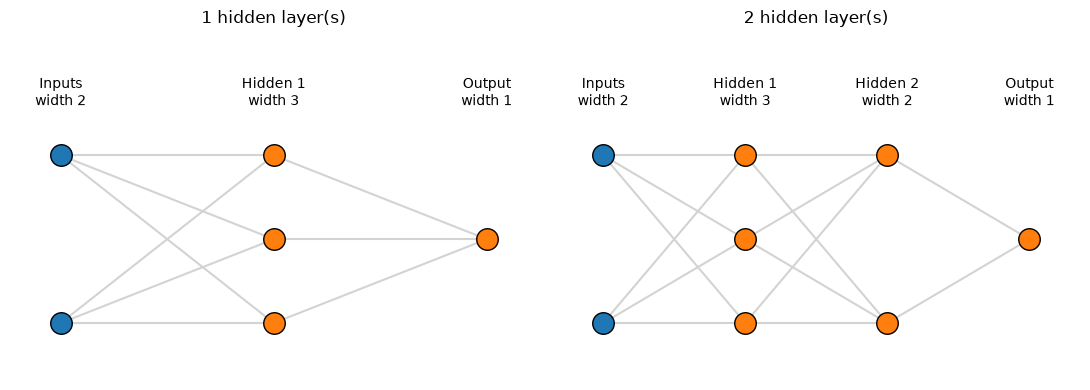

In [7]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, demo_widths in zip(axes, ([2, 3, 1], [2, 3, 2, 1])):
    demo_xs = np.linspace(0.08, 0.92, len(demo_widths))
    demo_layers = []
    for demo_index, (demo_x, demo_width) in enumerate(zip(demo_xs, demo_widths)):
        demo_ys = np.linspace(-0.25, 0.25, demo_width) if demo_width > 1 else np.array([0.0])
        demo_nodes = [(demo_x, value) for value in demo_ys]
        demo_layers.append(demo_nodes)
        demo_name = "Inputs" if demo_index == 0 else ("Output" if demo_index == len(demo_widths) - 1 else f"Hidden {demo_index}")
        ax.text(demo_x, 0.4, f"{demo_name}\nwidth {demo_width}", ha="center")
    for demo_left, demo_right in zip(demo_layers[:-1], demo_layers[1:]):
        for demo_start in demo_left:
            for demo_end in demo_right:
                ax.plot([demo_start[0], demo_end[0]], [demo_start[1], demo_end[1]], color="lightgray", zorder=1)
    for demo_index, demo_nodes in enumerate(demo_layers):
        ax.scatter(*np.array(demo_nodes).T, s=240, color=("tab:blue" if demo_index == 0 else "tab:orange"), edgecolors="black", zorder=2)
    ax.set(xlim=(-0.02, 1.02), ylim=(-0.42, 0.62), title=f"{len(demo_widths) - 2} hidden layer(s)")
    ax.axis("off")
fig.tight_layout()
plt.show()

### Representation and generalization are different experiments

The four exact XOR corners test whether a model can fit a small representational pattern. They are too few to establish broad generalization. A second dataset below samples a continuous square, labels opposite-sign coordinates as positive, and flips a small fraction of labels. This creates a reproducible nonlinear classification study with genuine ambiguity from label noise.

The split is fixed before modeling: 210 training examples, 75 validation examples, and 75 held-out test examples. If scaling inputs, use only training-derived means and scales. The generation code is a data definition, not a network solution.

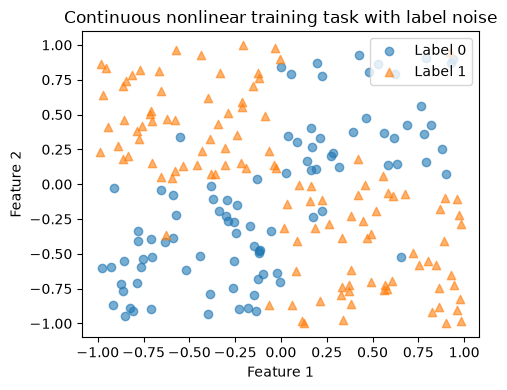

Target shape: (360, 1) split sizes: 210 75 75


In [8]:
demo_corners = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
demo_corner_Y = np.array([[0], [1], [1], [0]], dtype=float)
demo_rng = np.random.default_rng(606)
demo_X = demo_rng.uniform(-1.0, 1.0, size=(360, 2))
demo_Y = (demo_X[:, 0] * demo_X[:, 1] < 0).astype(float).reshape(-1, 1)
demo_flips = demo_rng.random(360) < 0.05
demo_Y[demo_flips, 0] = 1.0 - demo_Y[demo_flips, 0]
demo_order = demo_rng.permutation(360)
demo_train_ids, demo_validation_ids, demo_test_ids = demo_order[:210], demo_order[210:285], demo_order[285:]
fig, ax = plt.subplots(figsize=(5, 4))
for demo_label, demo_marker in [(0, "o"), (1, "^")]:
    demo_chosen = demo_train_ids[demo_Y[demo_train_ids, 0] == demo_label]
    ax.scatter(demo_X[demo_chosen, 0], demo_X[demo_chosen, 1], marker=demo_marker, alpha=0.6, label=f"Label {demo_label}")
ax.set(xlabel="Feature 1", ylabel="Feature 2", title="Continuous nonlinear training task with label noise")
ax.legend()
fig.tight_layout()
plt.show()
print("Target shape:", demo_Y.shape, "split sizes:", len(demo_train_ids), len(demo_validation_ids), len(demo_test_ids))

### Exercise 6.14 — Separate representation from successful optimization

**Type:** Experimental · **Answer:** Code

Train one- and two-hidden-layer models on the four exact XOR corners using several initialization seeds and declared budgets. Compare to a model without a nonlinear hidden layer. Plot probability surfaces and thresholded decisions over the input square.

**Expected outcome:** A representational comparison with all seeds, training settings, and failures reported. Do not interpret a failed individual run as proof that the architecture cannot express the pattern, or four-point accuracy as generalization evidence.

In [ ]:
# Your code for Exercise 6.14.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.14**

Use identical four-point data and report every seed, including failed fits.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.14**

Use **6.09–6.13** and the notebook's demonstration data **demo_corners** and **demo_corner_Y**. For this representation experiment, the same four points are passed in the validation slot only to satisfy the interface. They are not independent validation evidence, and no generalization claim follows. Report the fixed-budget last model rather than selecting a favorable checkpoint.

~~~python
import matplotlib.pyplot as plt

ref_xor_seeds = (0, 1, 2)
ref_xor_architectures = ((), (4,), (4, 3))
ref_grid_axis = np.linspace(0, 1, 90)
ref_gx, ref_gy = np.meshgrid(ref_grid_axis, ref_grid_axis)
ref_grid = np.column_stack((ref_gx.ravel(), ref_gy.ravel()))
ref_xor_results = []
for ref_hidden in ref_xor_architectures:
    fig, axes = plt.subplots(3, 2, figsize=(9, 10))
    for ref_row, ref_seed in enumerate(ref_xor_seeds):
        ref_run = fit_mlp(
            demo_corners, demo_corner_Y, demo_corners, demo_corner_Y,
            ref_hidden, activation="tanh", seed=ref_seed,
            learning_rate=.3, epochs=1200, batch_size=4, penalty=0,
        )
        ref_state = ref_run["last"]
        ref_loss, _ = mlp_objective(ref_state, demo_corners, demo_corner_Y)
        _, ref_P, _ = mlp_forward(demo_corners, ref_state)
        ref_accuracy = float(np.mean((ref_P >= .5) == demo_corner_Y))
        _, ref_surface, _ = mlp_forward(ref_grid, ref_state)
        ref_xor_results.append((ref_hidden, ref_seed, ref_loss, ref_accuracy))
        print("hidden, seed, last loss, exact-corner accuracy, all fit:",
              ref_hidden, ref_seed, ref_loss, ref_accuracy, ref_accuracy == 1.0)
        for ref_col, ref_values in enumerate(
            (ref_surface[:, 0], (ref_surface[:, 0] >= .5).astype(float))
        ):
            ax = axes[ref_row, ref_col]
            ax.contourf(ref_gx, ref_gy, ref_values.reshape(ref_gx.shape),
                        levels=np.linspace(0, 1, 11), vmin=0, vmax=1, cmap="coolwarm")
            ax.scatter(demo_corners[:, 0], demo_corners[:, 1],
                       c=demo_corner_Y[:, 0], vmin=0, vmax=1,
                       cmap="coolwarm", edgecolors="black")
            ax.set(xlabel="x1", ylabel="x2",
                   title=f"seed {ref_seed}: " + ("probability" if ref_col == 0 else "decision"))
    fig.suptitle(f"XOR: hidden widths {ref_hidden}, tanh, 1200 full-batch updates")
    fig.tight_layout()
    plt.show()
~~~

The affine baseline cannot strictly separate XOR. Hidden nonlinear units can represent it, but individual training runs can fail to find suitable parameters within the declared budget. Report such failures. The surfaces between the four training points show the fitted function's interpolation, not measured accuracy on unseen labels.

</details>

### Exercise 6.15 — Compare depth under controlled budgets

**Type:** Experimental · **Answer:** Code

On the continuous dataset, compare at least two widths for one hidden layer and two width pairs for two hidden layers. Record parameter counts, learning rates, examples processed, and at least three initialization seeds. Use validation data for selection and plot loss curves and decision boundaries.

**Expected outcome:** A comparison identifying which resources were matched and which changed, with variation across seeds rather than only the best run.

In [ ]:
# Your code for Exercise 6.15.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.15**

Match data exposure and update counts, while recording the changing parameter and arithmetic costs.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.15**

Use **6.09–6.13** and the notebook's continuous demonstration data and fixed split. All candidates use the same activation, rate, 180 epochs, and batches of 32. This matches examples processed and update count, while parameter count and work per example change. Compare mean final validation loss across the three seeds; do not select the most fortunate seed. Test observations are unused.

~~~python
ref_train_X, ref_train_Y = demo_X[demo_train_ids], demo_Y[demo_train_ids]
ref_val_X, ref_val_Y = demo_X[demo_validation_ids], demo_Y[demo_validation_ids]
ref_depth_architectures = ((4,), (8,), (4, 3), (6, 4))
ref_depth_seeds = (0, 1, 2)
ref_depth_runs, ref_architecture_scores = {}, []

def mlp_parameter_count(parameters):
    return sum(array.size for key in ("weights", "biases")
               for array in parameters[key])

for ref_hidden in ref_depth_architectures:
    ref_final_validation = []
    for ref_seed in ref_depth_seeds:
        ref_run = fit_mlp(
            ref_train_X, ref_train_Y, ref_val_X, ref_val_Y,
            ref_hidden, activation="tanh", seed=ref_seed, learning_rate=.1,
            epochs=180, batch_size=32, penalty=0,
        )
        ref_depth_runs[(ref_hidden, ref_seed)] = ref_run
        ref_end = ref_run["history"][-1]
        ref_final_validation.append(ref_end["validation_data_loss"])
        print("widths, parameters, seed, rate, updates, examples, train CE, val CE:",
              ref_hidden, mlp_parameter_count(ref_run["last"]), ref_seed, .1,
              ref_end["updates"], ref_end["examples"],
              ref_end["train_data_loss"], ref_end["validation_data_loss"])
    ref_mean = float(np.mean(ref_final_validation))
    ref_std = float(np.std(ref_final_validation, ddof=1))
    ref_architecture_scores.append((ref_mean, ref_hidden))
    print("Architecture mean validation CE and sample seed SD:",
          ref_hidden, ref_mean, ref_std)

ref_selected_hidden = min(ref_architecture_scores)[1]
print("Selected by mean final validation CE:", ref_selected_hidden)
ref_axis = np.linspace(-1, 1, 100)
ref_gx, ref_gy = np.meshgrid(ref_axis, ref_axis)
ref_grid = np.column_stack((ref_gx.ravel(), ref_gy.ravel()))
fig, axes = plt.subplots(4, 2, figsize=(10, 14))
for ref_row, ref_hidden in enumerate(ref_depth_architectures):
    for ref_seed in ref_depth_seeds:
        ref_history = ref_depth_runs[(ref_hidden, ref_seed)]["history"]
        axes[ref_row, 0].plot(
            [r["epoch"] for r in ref_history],
            [r["train_data_loss"] for r in ref_history],
            label=f"seed {ref_seed} train",
        )
        axes[ref_row, 0].plot(
            [r["epoch"] for r in ref_history],
            [r["validation_data_loss"] for r in ref_history],
            linestyle="--", label=f"seed {ref_seed} validation",
        )
    # Seed zero was declared for illustrative boundaries, not chosen by its score.
    _, ref_P, _ = mlp_forward(ref_grid, ref_depth_runs[(ref_hidden, 0)]["last"])
    axes[ref_row, 1].contourf(
        ref_gx, ref_gy, ref_P.reshape(ref_gx.shape),
        levels=np.linspace(0, 1, 11), cmap="coolwarm", vmin=0, vmax=1,
    )
    axes[ref_row, 1].contour(ref_gx, ref_gy, ref_P.reshape(ref_gx.shape),
                            levels=[.5], colors="black")
    axes[ref_row, 1].scatter(ref_val_X[:, 0], ref_val_X[:, 1],
                            c=ref_val_Y[:, 0], cmap="coolwarm", vmin=0, vmax=1,
                            edgecolors="black", s=15)
    axes[ref_row, 0].set(title=f"Hidden {ref_hidden}", xlabel="Epoch", ylabel="Data CE")
    axes[ref_row, 0].legend(fontsize=7)
    axes[ref_row, 1].set(title=f"Hidden {ref_hidden}, seed 0", xlabel="x1", ylabel="x2")
fig.tight_layout()
plt.show()
~~~

Report all rows, including poor fits and seed variation. The comparison supports conclusions only under this split, rate, activation, and budget. A parameter-matched or time-matched follow-up would answer a different, useful question; these runs alone cannot isolate a causal effect of depth.

</details>

### Exercise 6.16 — Investigate overfitting and regularization

**Type:** Experimental · **Answer:** Code

For a selected architecture, vary weight penalty and training budget using the fixed split. Compare training data loss, validation data loss, and the regularized training objective. Choose a configuration without consulting test results, then evaluate the final choice once on the test set.

**Expected outcome:** Clearly separated loss definitions and a documented model-selection decision. Report uncertainty from the finite split and optimization variability.

In [ ]:
# Your code for Exercise 6.16.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.16**

Select using validation data, then freeze the configuration and seed before inspecting the test partition.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.16**

Use **6.09–6.15**, including the architecture selected there. Compare penalties and fixed budgets with the same three seeds. Select by mean final validation data loss, then use the predeclared seed zero's last snapshot for a single final test evaluation. A best-checkpoint policy would also be valid if declared and compared consistently, but this experiment uses fixed budgets.

~~~python
ref_regularization_runs, ref_configuration_scores = {}, []
for ref_penalty in (0.0, .001, .03):
    for ref_budget in (50, 200):
        ref_validation_losses = []
        for ref_seed in (0, 1, 2):
            ref_run = fit_mlp(
                ref_train_X, ref_train_Y, ref_val_X, ref_val_Y,
                ref_selected_hidden, seed=ref_seed, learning_rate=.1,
                epochs=ref_budget, batch_size=32, penalty=ref_penalty,
            )
            ref_regularization_runs[(ref_penalty, ref_budget, ref_seed)] = ref_run
            ref_end = ref_run["history"][-1]
            ref_validation_losses.append(ref_end["validation_data_loss"])
            print("penalty, epochs, seed, train CE, train objective, val CE:",
                  ref_penalty, ref_budget, ref_seed,
                  ref_end["train_data_loss"], ref_end["train_objective"],
                  ref_end["validation_data_loss"])
        ref_mean = float(np.mean(ref_validation_losses))
        ref_std = float(np.std(ref_validation_losses, ddof=1))
        ref_configuration_scores.append((ref_mean, ref_penalty, ref_budget))
        print("Mean validation CE and seed SD:", ref_penalty, ref_budget, ref_mean, ref_std)

_, ref_final_penalty, ref_final_budget = min(ref_configuration_scores)
ref_final_run = ref_regularization_runs[(ref_final_penalty, ref_final_budget, 0)]
ref_final_state = ref_final_run["last"]
print("Frozen choice: widths, penalty, epochs, seed:",
      ref_selected_hidden, ref_final_penalty, ref_final_budget, 0)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ref_penalty in (0.0, .001, .03):
    ref_history = ref_regularization_runs[(ref_penalty, 200, 0)]["history"]
    for ax, ref_key in zip(axes, ("train_data_loss", "train_objective",
                                  "validation_data_loss")):
        ax.plot([r["epoch"] for r in ref_history],
                [r[ref_key] for r in ref_history], label=f"penalty {ref_penalty:g}")
        ax.set(xlabel="Epoch", ylabel=ref_key)
        ax.legend()
fig.tight_layout()
plt.show()

# Final test access occurs only after the selection above.
ref_test_X, ref_test_Y = demo_X[demo_test_ids], demo_Y[demo_test_ids]
ref_test_logits, ref_test_P, _ = mlp_forward(ref_test_X, ref_final_state)
ref_test_loss = float(np.mean(
    np.logaddexp(0, ref_test_logits) - ref_test_Y * ref_test_logits
))
ref_test_accuracy = float(np.mean((ref_test_P >= .5) == ref_test_Y))
print("One final test evaluation: data CE, accuracy, n:",
      ref_test_loss, ref_test_accuracy, len(ref_test_Y))
~~~

The regularized objective includes a parameter-dependent penalty and is not directly the same quantity as either data loss. Read the three curves accordingly. Seed spread describes optimization variability for this split, not uncertainty from sampling other datasets. The finite, repeatedly consulted validation set can favor a configuration by chance; the single small test split also has sampling uncertainty. Preserve its final role when extending the investigation rather than repeatedly retuning against it.

</details>

## 7. Interpretation and critical analysis

Hidden units compose learned features, but their identities are not unique. Permuting hidden units together with their corresponding outgoing connections leaves predictions unchanged. Different seeds can therefore produce different parameter matrices with similar functions, even before considering optimization differences.

Unlike linear logistic regression, an MLP objective is generally nonconvex in all weights jointly. Tanh is smooth, while ReLU introduces corners. Gradient descent can encounter flat regions, saturation, poor conditioning, and sensitivity to initialization. Finite-difference agreement establishes local derivative consistency for the implemented objective; it does not ensure a global optimum.

A deeper model can offer useful compositional structure but also changes parameter count, gradient paths, runtime, and selection effort. A lower training loss can reflect greater ability to memorize noisy labels. Compare validation behavior, decision geometry, stability across seeds, and computational work before drawing a practical conclusion.

### Exercise 6.17 — Explain a widening train–validation gap

**Type:** Critical · **Answer:** Markdown

Training data loss keeps falling while validation data loss rises. Give at least two plausible explanations or investigations, distinguishing overfitting from an evaluation/implementation error. Explain what a best validation snapshot does and does not establish.

**Expected outcome:** A diagnosis grounded in fixed splits, loss definitions, snapshot correctness, and model capacity.

**Your response to Exercise 6.17**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.17**

First establish that the two curves use comparable losses and correct parameter snapshots.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.17**

One plausible explanation is overfitting: additional optimization fits training-specific fluctuations or label noise, reducing training data loss while hurting validation predictions. Inspect capacity, regularization, budgets, and seed variation on a fixed split.

A different possibility is an evaluation error or mismatch. Verify that both curves are full-data mean cross-entropies rather than one including a penalty or the last mini-batch only. Check preprocessing fit only on training data, label alignment, deterministic evaluation, and that retained parameters are copies. A distribution difference or a small noisy validation sample can also contribute.

A best validation snapshot identifies the lowest observed validation loss among the evaluated states under that selection policy. It does not prove that the model generalizes better to the population, that optimization found a global optimum, or that repeated validation selection has not overfit the split. Freeze the policy and use an independent final test.

</details>

### Exercise 6.18 — Evaluate a claim about depth

**Type:** Critical · **Answer:** Markdown

A two-hidden-layer network outperforms one narrower one-hidden-layer network on a single seed. Explain what comparisons are missing before claiming that the extra depth caused the improvement.

**Expected outcome:** A proposed study controlling parameter count or documenting its change, work budget, hyperparameter selection, and seed variability.

**Your response to Exercise 6.18**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.18**

Depth changed alongside width and probably parameter count.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.18**

The observation establishes that those two runs differ in score. To attribute an improvement to added depth, compare several widths in each depth family, report or approximately match parameter counts, and record arithmetic or time costs as well as examples and updates.

Use identical data partitions, preprocessing, loss definitions, activation policies, and evaluation metrics. Give each architecture a declared, comparable hyperparameter-selection effort rather than tuning only one. Repeat across initialization seeds and report distributions or means with spread, including failed runs. Evaluate the selected configurations on held-out data after choices are frozen.

Even these controls bound the conclusion to the studied tasks, architectures, and budgets. One favorable seed against one narrow baseline cannot establish that deeper networks generally perform better.

</details>

## 8. Review questions and knowledge checks

### Exercise 6.19 — Explain the complete learning pipeline

**Type:** Conceptual · **Answer:** Markdown

Describe data splitting, initialization, forward computation, objective evaluation, backpropagation, parameter updates, validation selection, and final testing. Identify which steps are allowed to use each data partition.

**Expected outcome:** A coherent end-to-end account that separates differentiation, optimization, model selection, and evaluation.

**Your response to Exercise 6.19**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.19**

Assign a role to each partition before fitting anything.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.19**

1. Split observations into training, validation, and test partitions with the sampling scheme appropriate to the task. Fit any preprocessing statistics on training data and apply those fixed transformations elsewhere.
2. Initialize parameters from the declared architecture and random seed. Initialization should not use evaluation labels.
3. On a training batch, compute affine maps, hidden activations, output logits, and probabilities. Evaluate the specified training objective, including any declared weight penalty.
4. Backpropagate that scalar objective at the same parameter snapshot. Store every gradient, then apply the optimizer update. Repeat within the declared budget.
5. At checkpoints, evaluate full training and validation data losses and the chosen metrics. Validation may select snapshots, hyperparameters, or architectures, but its labels do not enter training gradients here.
6. Freeze the configuration, preprocessing, threshold, and snapshot-selection policy. Evaluate the final choice on test data once and report the setting and uncertainty.

Differentiation computes a local derivative; optimization changes parameters; validation chooses among models or states; final testing estimates performance after those choices. The test partition is excluded from all earlier fitting and selection.

</details>

### Exercise 6.20 — Verify invariance under a hidden-unit permutation

**Type:** Mathematical · **Answer:** Markdown

For one hidden layer, suppose you reorder the hidden units. Describe the matching reordering of the first-layer weights/biases and second-layer weights that preserves the output. Justify the statement using shapes or component sums.

**Expected outcome:** A mathematically justified example of different parameters representing the same function.

**Your response to Exercise 6.20**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 6.20**

Match each reordered hidden feature with its original outgoing weight.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 6.20**

Let a permutation $\pi$ list old hidden indices in their new order. Define
$$
W'^{[1]}_{kj}=W^{[1]}_{k,\pi(j)},\quad
b'^{[1]}_j=b^{[1]}_{\pi(j)},\quad
W'^{[2]}_{j1}=W^{[2]}_{\pi(j),1},\quad b'^{[2]}=b^{[2]}.
$$
The elementwise activation then gives $A'^{[1]}_{ij}=A^{[1]}_{i,\pi(j)}$. Therefore
$$
\sum_j A'^{[1]}_{ij}W'^{[2]}_{j1}+b'^{[2]}
=\sum_j A^{[1]}_{i,\pi(j)}W^{[2]}_{\pi(j),1}+b^{[2]}
=\sum_r A^{[1]}_{ir}W^{[2]}_{r1}+b^{[2]}.
$$
The last equality just reorders the same summands. Shapes remain $(d,h)$, $(h,)$, $(h,1)$, and $(1,)$. Thus logits and sigmoid probabilities are unchanged for every input. Different parameter arrays can describe exactly the same function; this is one source of parameter nonuniqueness.

</details>

## 9. Summary and next learning steps

You have assembled one- and two-hidden-layer binary classifiers from affine maps, nonlinearities, a stable probability loss, reverse-mode differentiation, and an optimizer. Shape contracts and one explicit averaging convention keep the derivation aligned with implementation. Initialization, representation capacity, validation, and computational budgets determine what an experiment can support.

Before considering the curriculum complete, ensure that both architectures pass your tiny numerical checks, every result records a seed and loss convention, and your final model choice was made before test evaluation. Keep completed answers and exploratory outputs on a study branch.

Further studies can extend this foundation to continuous outputs, multiple classes, other regularizers, or alternative optimizers. For continuous outputs, a linear final activation and half-MSE give output sensitivity $(A^{[L]}-Y)/n$ instead of the sigmoid/cross-entropy pair; the hidden-layer rules stay local. These are possible future projects, not additional completed models in this notebook.